# Constraint Satisfaction Problem : Graph coloring


## Create Data

We can create a planar graph with $n$ vertices by randomly placing $n$ points in 2-dimensional Euclidean space and then performing a [Delaunay triangulation](https://en.wikipedia.org/wiki/Delaunay_triangulation).

findfont: Failed to find font weight heavy, now using 700.


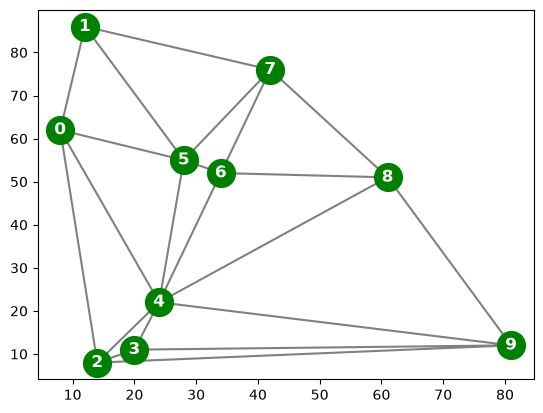

In [1]:
import time
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay

np.random.seed(1111)

# create points and sort them by 
n = 10
points = np.random.randint(100, size=(n, 2))
o = np.argsort(points[:,0])
points = points[o,:]


# triangulate
tri = Delaunay(points)


# plot
plt.triplot(points[:,0], points[:,1], tri.simplices, color = "gray")
plt.plot(points[:,0], points[:,1], 'o', color = "green", markersize = 20)

for i in range(len(points)):
       plt.annotate(i, points[i,:], 
        color='white', fontsize="large", weight='heavy',
        horizontalalignment='center', verticalalignment='center')

plt.show()

The triangulation can be converted into a list with an array of neighbor vertex indices for each point (see man page for [scipy.spatial.Delaunay](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.Delaunay.html)). 

In [2]:
(indptr, indices) = tri.vertex_neighbor_vertices

neighbors = []

for k in range(len(indptr)-1):
    neighbors.append(np.sort(indices[indptr[k]:indptr[k+1]]))
    
neighbors

[array([1, 2, 4, 5], dtype=int32),
 array([0, 5, 7], dtype=int32),
 array([0, 3, 4, 9], dtype=int32),
 array([2, 4, 9], dtype=int32),
 array([0, 2, 3, 5, 6, 8, 9], dtype=int32),
 array([0, 1, 4, 6, 7], dtype=int32),
 array([4, 5, 7, 8], dtype=int32),
 array([1, 5, 6, 8], dtype=int32),
 array([4, 6, 7, 9], dtype=int32),
 array([2, 3, 4, 8], dtype=int32)]

The first row are the indices for the points neighboring point 0.

## Define CSP

The problem is defined as a dictionary with variable names, a dictionary with domain values for each variable and a set of binary  not-equal constraints (tuples of variables that are not allowed to have the same value).  

## BÀI 1 — BIỂU DIỄN CSP VÀ SINH ĐỒ THỊ CẦN TÔ MÀU

Mô hình bài toán bằng ba thành phần:
- **Biến \(X\)**: mỗi đỉnh của đồ thị là một biến \(X_i\).
- **Miền \(D\)**: tập màu được phép, ví dụ 3 màu hoặc 4 màu.
- **Ràng buộc \(C_{ij}\)**: nếu hai đỉnh \(i\) và \(j\) có cạnh nối thì \(X_i \ne X_j\).

Đồ thị được tạo từ các điểm ngẫu nhiên và phép tam giác hóa Delaunay. Các ô lệnh tiếp theo tạo danh sách biến, miền màu và tập ràng buộc cho CSP.

In [3]:
variables = [str(var) for var in range(n)]

domain = ['red', 'blue', 'green', 'orange']
domains = {v: domain.copy() for v in variables}

# Store each undirected edge exactly once.
edges = set()
for i, nbrs in enumerate(neighbors):
    for j in nbrs:
        if i < int(j):
            edges.add((str(i), str(j)))

constraints = sorted(edges)
csp = {'variables': variables, 'domains': domains, 'constraints': constraints}
print(f"Vertices: {len(variables)} | Edges/constraints: {len(constraints)}")
csp


Vertices: 10 | Edges/constraints: 21


{'variables': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'],
 'domains': {'0': ['red', 'blue', 'green', 'orange'],
  '1': ['red', 'blue', 'green', 'orange'],
  '2': ['red', 'blue', 'green', 'orange'],
  '3': ['red', 'blue', 'green', 'orange'],
  '4': ['red', 'blue', 'green', 'orange'],
  '5': ['red', 'blue', 'green', 'orange'],
  '6': ['red', 'blue', 'green', 'orange'],
  '7': ['red', 'blue', 'green', 'orange'],
  '8': ['red', 'blue', 'green', 'orange'],
  '9': ['red', 'blue', 'green', 'orange']},
 'constraints': [('0', '1'),
  ('0', '2'),
  ('0', '4'),
  ('0', '5'),
  ('1', '5'),
  ('1', '7'),
  ('2', '3'),
  ('2', '4'),
  ('2', '9'),
  ('3', '4'),
  ('3', '9'),
  ('4', '5'),
  ('4', '6'),
  ('4', '8'),
  ('4', '9'),
  ('5', '6'),
  ('5', '7'),
  ('6', '7'),
  ('6', '8'),
  ('7', '8'),
  ('8', '9')]}

## BÀI 2 — KIỂM TRA TÍNH ĐẦY ĐỦ VÀ TÍNH NHẤT QUÁN

- `complete(assignment, csp)`: trả về `True` khi tất cả biến trong CSP đã được gán giá trị.
- `consistent(assignment, csp)`: trả về `True` khi không có ràng buộc nào bị vi phạm bởi các biến đã được gán.

Hai tính chất này không giống nhau: một phép gán có thể **đầy đủ nhưng không nhất quán**, chẳng hạn khi hai đỉnh kề nhau được gán cùng màu.

In [4]:
def complete(assignment, csp):
    return all(v in assignment for v in csp['variables'])

print("complete({}, csp) =", complete({}, csp))
full_assignment = {v: 'red' for v in csp['variables']}
print("complete(full assignment, csp) =", complete(full_assignment, csp))


complete({}, csp) = False
complete(full assignment, csp) = True


In [5]:
def consistent(assignment, csp):
    # A constraint is relevant only when both endpoints have been assigned.
    for u, v in csp['constraints']:
        if u in assignment and v in assignment and assignment[u] == assignment[v]:
            return False
    return True

print("consistent({}, csp) =", consistent({}, csp))
print("Adjacent same color -> False:",
      consistent({'0': 'red', '1': 'red'}, csp) if ('0', '1') in csp['constraints' ] else
      "edge (0,1) is not in this random graph; test an actual edge below")
u, v = csp['constraints'][0]
print(f"consistent({{{u}: red, {v}: red}}) =", consistent({u: 'red', v: 'red'}, csp))
print("Non-adjacent equal colors can be consistent:",
      consistent({csp['variables'][0]: 'red'}, csp))


consistent({}, csp) = True
Adjacent same color -> False: False
consistent({0: red, 1: red}) = False
Non-adjacent equal colors can be consistent: True


## BÀI 3 — BACKTRACKING SEARCH VÀ THỨ TỰ CHỌN BIẾN

Cài đặt thuật toán tìm kiếm quay lui để thử gán màu cho từng đỉnh. Khi phép gán vi phạm ràng buộc, thuật toán quay lui và thử giá trị khác.

Các heuristic được sử dụng:
- **MRV (Minimum Remaining Values)**: chọn biến chưa gán có ít màu hợp lệ nhất.
- **Degree Heuristic**: khi hòa, ưu tiên biến có nhiều láng giềng chưa gán hơn.
- **LCV (Least Constraining Value)**: thử màu làm hạn chế lựa chọn của các biến lân cận ít nhất.

In [6]:
def legal_colors(var, assignment, csp):
    '''Return colors that do not conflict with already assigned neighbors.'''
    used = set()
    for u, v in csp['constraints']:
        if u == var and v in assignment:
            used.add(assignment[v])
        elif v == var and u in assignment:
            used.add(assignment[u])
    return [color for color in csp['domains'][var] if color not in used]

def select_unassigned_var(assignment, csp, domains=None):
    '''MRV: choose the unassigned variable with the fewest legal values.
    Degree heuristic breaks ties by preferring the most constrained/high-degree vertex.
    '''
    unassigned = [v for v in csp['variables'] if v not in assignment]
    if not unassigned:
        return None
    if domains is None:
        domains = {v: legal_colors(v, assignment, csp) for v in unassigned}
    degree = {v: sum(1 for a, b in csp['constraints']
                     if (a == v and b not in assignment) or (b == v and a not in assignment))
              for v in unassigned}
    return min(unassigned, key=lambda v: (len(domains[v]), -degree[v], int(v)))

def order_domain(var, assignment, csp, domains=None):
    '''Least-constraining value (LCV): try the color that rules out the fewest
    choices for neighboring unassigned variables first.'''
    colors = (domains[var].copy() if domains is not None
              else legal_colors(var, assignment, csp))
    def impact(color):
        eliminated = 0
        for u, v in csp['constraints']:
            other = v if u == var else (u if v == var else None)
            if other is not None and other not in assignment:
                other_domain = (domains[other] if domains is not None
                                else legal_colors(other, assignment, csp))
                if color in other_domain:
                    eliminated += 1
        return eliminated
    return sorted(colors, key=lambda color: (impact(color), color))

print("MRV-selected variable:", select_unassigned_var({'0': 'red', '1': 'blue'}, csp))


MRV-selected variable: 5


In [7]:
VERBOSE = False
COUNT = 0

def backtrack_search(csp, use_mrv=True, use_lcv=True, use_forward_checking=False,
                     max_nodes=500_000):
    '''Backtracking CSP solver.
    COUNT records recursive search nodes; attempted assignments are also recorded.
    Returns (assignment or None, stats). A node limit prevents pathological runtimes.
    '''
    stats = {'nodes': 0, 'attempts': 0, 'backtracks': 0, 'cutoff': False}
    initial_domains = {v: list(csp['domains'][v]) for v in csp['variables']}

    def recurse(assignment, current_domains):
        stats['nodes'] += 1
        if stats['nodes'] > max_nodes:
            stats['cutoff'] = True
            return None
        if complete(assignment, csp):
            return assignment.copy()

        if use_mrv:
            var = select_unassigned_var(assignment, csp, current_domains)
        else:
            var = next(v for v in csp['variables'] if v not in assignment)

        values = (order_domain(var, assignment, csp, current_domains) if use_lcv
                  else current_domains[var].copy())
        for value in values:
            stats['attempts'] += 1
            if value not in current_domains[var]:
                continue
            assignment[var] = value
            if consistent(assignment, csp):
                next_domains = {v: d.copy() for v, d in current_domains.items()}
                failed = False
                if use_forward_checking:
                    for u, v in csp['constraints']:
                        other = v if u == var else (u if v == var else None)
                        if other is not None and other not in assignment:
                            next_domains[other] = [x for x in next_domains[other] if x != value]
                            if not next_domains[other]:
                                failed = True
                                break
                if not failed:
                    result = recurse(assignment, next_domains)
                    if result is not None:
                        return result
            del assignment[var]
            stats['backtracks'] += 1
            if stats['cutoff']:
                return None
        return None

    result = recurse({}, initial_domains)
    return result, stats


## Chạy thuật toán Backtracking trên đồ thị đã tạo

Ô lệnh tiếp theo giải bài toán bằng MRV + LCV + Forward Checking, đồng thời đo thời gian chạy và thống kê số nút tìm kiếm, số lần thử gán và số lần quay lui.

In [8]:
# Solve the current graph using MRV + LCV + Forward Checking.
start = time.perf_counter()
res, search_stats = backtrack_search(csp, use_mrv=True, use_lcv=True,
                                     use_forward_checking=True)
elapsed = time.perf_counter() - start
print("Solution:", res)
print("Search statistics:", search_stats)
print(f"Elapsed: {elapsed:.6f} seconds")


Solution: {'4': 'blue', '5': 'green', '0': 'orange', '2': 'green', '6': 'orange', '7': 'blue', '1': 'red', '9': 'orange', '3': 'red', '8': 'green'}
Search statistics: {'nodes': 11, 'attempts': 10, 'backtracks': 0, 'cutoff': False}
Elapsed: 0.000678 seconds


### Trực quan hóa kết quả tô màu

Mỗi đỉnh được tô theo màu mà thuật toán tìm được. Nếu không tìm thấy nghiệm trong giới hạn tìm kiếm, notebook sẽ thông báo thay vì hiển thị một phép tô màu chưa được xác nhận.

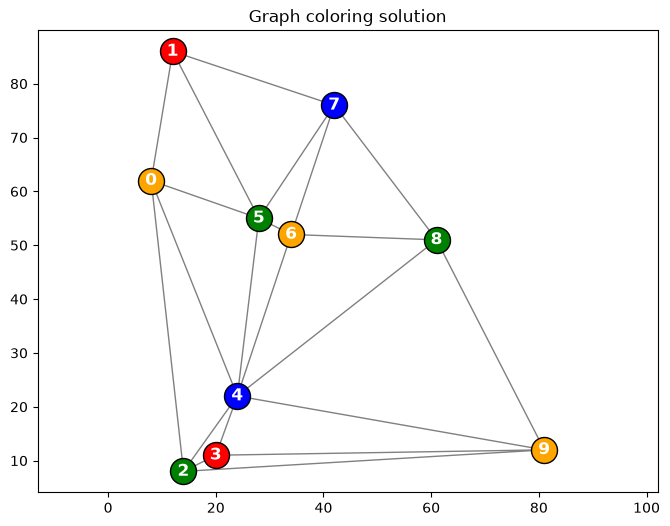

In [9]:
plt.figure(figsize=(8, 6))
plt.triplot(points[:, 0], points[:, 1], tri.simplices, color="gray", linewidth=1)
if res is not None:
    for i in range(len(points)):
        plt.scatter(points[i, 0], points[i, 1], s=350, c=res[str(i)],
                    edgecolors='black', zorder=3)
        plt.annotate(i, points[i, :], color='white', fontsize='large',
                     weight='heavy', ha='center', va='center', zorder=4)
else:
    plt.scatter(points[:, 0], points[:, 1], s=200, c='gray', edgecolors='black')
    print("No solution found within the search limit.")
plt.title("Graph coloring solution")
plt.axis("equal")
plt.show()


## BÀI 4 — FORWARD CHECKING VÀ MIN-CONFLICTS

Phần này bổ sung hai kỹ thuật để cải thiện hoặc thay đổi cách tìm kiếm:

1. **Forward Checking (FC)**: sau khi gán màu cho một đỉnh, loại màu đó khỏi miền của các đỉnh kề chưa được gán. Nếu miền của một đỉnh trở thành rỗng, quay lui ngay.
2. **Min-Conflicts**: bắt đầu bằng một phép gán đầy đủ, sau đó chọn một đỉnh đang xung đột và đổi sang màu làm giảm số xung đột. Nếu không tìm được nghiệm trong số bước cho phép, thuật toán có thể khởi động lại với phép gán ngẫu nhiên mới.

Notebook cũng so sánh Backtracking cơ bản, MRV + LCV, MRV + LCV + FC và Min-Conflicts trên nhiều đồ thị, số màu và seed ngẫu nhiên.

### Cài đặt thuật toán Min-Conflicts

Thuật toán chọn ngẫu nhiên một biến đang xung đột và tìm màu có số xung đột thấp nhất với các đỉnh kề. Nếu hết số bước quy định mà chưa tìm được nghiệm, thuật toán khởi động lại cho đến khi đạt giới hạn số lần khởi động lại.

In [10]:
def build_csp_from_points(n_vertices, seed, colors):
    rng = np.random.default_rng(seed)
    # Continuous coordinates avoid duplicate points, which can break triangulation.
    pts = rng.random((n_vertices, 2))
    triangulation = Delaunay(pts)
    adj = [set() for _ in range(n_vertices)]
    for simplex in triangulation.simplices:
        for i in range(3):
            u, v = int(simplex[i]), int(simplex[(i + 1) % 3])
            adj[u].add(v); adj[v].add(u)
    vars_ = [str(i) for i in range(n_vertices)]
    edge_set = {(str(u), str(v)) for u in range(n_vertices) for v in adj[u] if u < v}
    return pts, triangulation, adj, {
        'variables': vars_,
        'domains': {v: list(colors) for v in vars_},
        'constraints': sorted(edge_set)
    }

def min_conflicts(csp, max_steps=20_000, max_restarts=20, seed=0):
    rng = random.Random(seed)
    variables = csp['variables']
    domains = csp['domains']
    neighbors_map = {v: set() for v in variables}
    for u, v in csp['constraints']:
        neighbors_map[u].add(v); neighbors_map[v].add(u)

    total_steps, uphill_moves, restarts = 0, 0, 0
    for restart in range(max_restarts + 1):
        assignment = {v: rng.choice(domains[v]) for v in variables}
        for step in range(max_steps):
            conflicted = [v for v in variables if any(
                assignment[v] == assignment[w] for w in neighbors_map[v])]
            if not conflicted:
                return assignment, {'steps': total_steps, 'uphill_moves': uphill_moves,
                                    'restarts': restarts, 'success': True}
            var = rng.choice(conflicted)
            scores = {color: sum(assignment[w] == color for w in neighbors_map[var])
                      for color in domains[var]}
            best_score = min(scores.values())
            best_colors = [color for color, score in scores.items() if score == best_score]
            old_score = scores[assignment[var]]
            new_color = rng.choice(best_colors)
            if scores[new_color] >= old_score:
                uphill_moves += 1
            assignment[var] = new_color
            total_steps += 1
        if restart < max_restarts:
            restarts += 1
    return None, {'steps': total_steps, 'uphill_moves': uphill_moves,
                  'restarts': restarts, 'success': False}

def valid_coloring(assignment, csp):
    return assignment is not None and complete(assignment, csp) and consistent(assignment, csp)

# Smoke test the local-search solver on the current graph.
mc_res, mc_stats = min_conflicts(csp, seed=1111)
print("Min-Conflicts valid:", valid_coloring(mc_res, csp))
print("Min-Conflicts statistics:", mc_stats)


Min-Conflicts valid: True
Min-Conflicts statistics: {'steps': 7, 'uphill_moves': 3, 'restarts': 0, 'success': True}


### Kiểm thử tự động cho `complete()` và `consistent()`

Các kiểm thử xác nhận những trường hợp sau:
- Phép gán rỗng chưa đầy đủ.
- Phép gán cho tất cả biến là đầy đủ, kể cả khi có thể vi phạm ràng buộc.
- Hai đỉnh kề nhau cùng màu tạo ra phép gán không nhất quán.
- Hai đỉnh kề nhau khác màu không vi phạm ràng buộc giữa hai đỉnh đó.

In [11]:
# Three explicit tests for completeness and consistency.
test_complete_empty = complete({}, csp) is False
test_complete_full = complete({v: csp['domains'][v][0] for v in csp['variables']}, csp) is True
u, v = csp['constraints'][0]
test_edge_conflict = consistent({u: 'red', v: 'red'}, csp) is False
test_partial_consistent = consistent({u: 'red', v: 'blue'}, csp) is True
tests = {
    'empty assignment is incomplete': test_complete_empty,
    'full assignment is complete regardless of conflicts': test_complete_full,
    'same color on an edge is inconsistent': test_edge_conflict,
    'different colors on an edge are consistent': test_partial_consistent,
}
for name, passed in tests.items():
    print(('PASS' if passed else 'FAIL'), '-', name)
assert all(tests.values())


PASS - empty assignment is incomplete
PASS - full assignment is complete regardless of conflicts
PASS - same color on an edge is inconsistent
PASS - different colors on an edge are consistent


### Thực nghiệm so sánh các thuật toán

Thực nghiệm chạy trên các đồ thị có số đỉnh khác nhau, sử dụng 3 màu và 4 màu cùng nhiều seed để giảm phụ thuộc vào một trường hợp ngẫu nhiên duy nhất.

Các chỉ số được ghi nhận:
- Tỷ lệ tìm được nghiệm hợp lệ.
- Số lần thử gán, số nút tìm kiếm và số lần quay lui đối với Backtracking.
- Số bước, số lần di chuyển không cải thiện và số lần khởi động lại đối với Min-Conflicts.
- Thời gian chạy trung bình và tỷ lệ chạm giới hạn tìm kiếm.

**Lưu ý:** không tìm được nghiệm trong giới hạn thời gian hoặc số nút không đồng nghĩa với việc đã chứng minh bài toán vô nghiệm.

In [12]:
def run_benchmark(sizes=(10, 15, 20, 25), color_counts=(3, 4), seeds=(11, 22, 33),
                  max_nodes=100_000, mc_steps=5_000, mc_restarts=10):
    rows = []
    for nv in sizes:
        for k in color_counts:
            for seed in seeds:
                colors = ['red', 'blue', 'green', 'orange'][:k]
                pts, triangulation, adj, instance = build_csp_from_points(nv, seed, colors)
                edge_count = len(instance['constraints'])
                algorithms = [
                    ('Backtracking baseline', dict(use_mrv=False, use_lcv=False, use_forward_checking=False)),
                    ('MRV + LCV', dict(use_mrv=True, use_lcv=True, use_forward_checking=False)),
                    ('MRV + LCV + FC', dict(use_mrv=True, use_lcv=True, use_forward_checking=True)),
                ]
                for name, kwargs in algorithms:
                    t0 = time.perf_counter()
                    sol, stats = backtrack_search(instance, max_nodes=max_nodes, **kwargs)
                    duration = time.perf_counter() - t0
                    rows.append({'n': nv, 'colors': k, 'seed': seed, 'edges': edge_count,
                                 'algorithm': name, 'success': valid_coloring(sol, instance),
                                 'attempts': stats['attempts'], 'nodes': stats['nodes'],
                                 'backtracks': stats['backtracks'], 'uphill_moves': None,
                                 'restarts': None, 'seconds': duration,
                                 'cutoff': stats['cutoff']})
                t0 = time.perf_counter()
                sol, stats = min_conflicts(instance, max_steps=mc_steps,
                                           max_restarts=mc_restarts, seed=seed)
                duration = time.perf_counter() - t0
                rows.append({'n': nv, 'colors': k, 'seed': seed, 'edges': edge_count,
                             'algorithm': 'Min-Conflicts', 'success': valid_coloring(sol, instance),
                             'attempts': None, 'nodes': None, 'backtracks': None,
                             'uphill_moves': stats['uphill_moves'], 'restarts': stats['restarts'],
                             'seconds': duration, 'cutoff': False})
    return pd.DataFrame(rows)

import pandas as pd
results = run_benchmark(sizes=(10, 15, 20), seeds=(11, 22, 33), max_nodes=30000, mc_steps=3000, mc_restarts=8)
display(results)


,n,colors,seed,edges,algorithm,success,attempts,nodes,backtracks,uphill_moves,restarts,seconds,cutoff
0,10,3,11,23,Backtracking baseline,False,354.0,118.0,354.0,NaN,NaN,0.000891,False
1,10,3,11,23,MRV + LCV,False,246.0,82.0,246.0,NaN,NaN,0.002256,False
2,10,3,11,23,MRV + LCV + FC,False,15.0,10.0,15.0,NaN,NaN,0.000345,False
3,10,3,11,23,Min-Conflicts,False,NaN,NaN,NaN,26965.0,8.0,0.513053,False
4,10,3,22,20,Backtracking baseline,False,1056.0,352.0,1056.0,NaN,NaN,0.004038,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,20,4,22,46,Min-Conflicts,True,NaN,NaN,NaN,20.0,0.0,0.000976,False
68,20,4,33,48,Backtracking baseline,True,340.0,94.0,320.0,NaN,NaN,0.001995,False
69,20,4,33,48,MRV + LCV,True,50.0,21.0,30.0,NaN,NaN,0.001829,False
70,20,4,33,48,MRV + LCV + FC,True,20.0,21.0,0.0,NaN,NaN,0.002119,False


In [13]:
# Aggregate results over the random instances for each n and number of colors.
summary = (results.groupby(['n', 'colors', 'algorithm'], as_index=False)
           .agg(avg_edges=('edges', 'mean'),
                success_rate=('success', 'mean'),
                avg_attempts=('attempts', 'mean'),
                avg_nodes=('nodes', 'mean'),
                avg_uphill_moves=('uphill_moves', 'mean'),
                avg_restarts=('restarts', 'mean'),
                avg_seconds=('seconds', 'mean'),
                cutoff_rate=('cutoff', 'mean')))
display(summary.round(3))

print("Mean edge count by n (averaged over color counts and seeds):")
display(results[['n', 'seed', 'edges']].drop_duplicates()
        .groupby('n', as_index=False).agg(avg_edges=('edges', 'mean')).round(2))


,n,colors,algorithm,avg_edges,success_rate,avg_attempts,avg_nodes,avg_uphill_moves,avg_restarts,avg_seconds,cutoff_rate
0,10,3,Backtracking baseline,21.333,0.0,675.000,225.000,NaN,NaN,0.002,0.0
1,10,3,MRV + LCV,21.333,0.0,393.000,131.000,NaN,NaN,0.006,0.0
2,10,3,MRV + LCV + FC,21.333,0.0,31.000,26.000,NaN,NaN,0.001,0.0
3,10,3,Min-Conflicts,21.333,0.0,NaN,NaN,26964.667,8.0,0.498,0.0
4,10,4,Backtracking baseline,21.333,1.0,22.667,11.000,NaN,NaN,0.000,0.0
5,10,4,MRV + LCV,21.333,1.0,24.333,11.000,NaN,NaN,0.000,0.0
6,10,4,MRV + LCV + FC,21.333,1.0,10.000,11.000,NaN,NaN,0.000,0.0
7,10,4,Min-Conflicts,21.333,1.0,NaN,NaN,6.000,0.0,0.000,0.0
8,15,3,Backtracking baseline,34.333,0.0,2241.000,747.000,NaN,NaN,0.011,0.0
9,15,3,MRV + LCV,34.333,0.0,2631.000,877.000,NaN,NaN,0.055,0.0


Mean edge count by n (averaged over color counts and seeds):


,n,avg_edges
0,10,21.33
1,15,34.33
2,20,48.00


## BIỂU ĐỒ TÔ MÀU CHO BÀI 4 — FORWARD CHECKING VÀ MIN-CONFLICTS

Biểu đồ dưới đây hiển thị kết quả tô màu hợp lệ cho đồ thị đang dùng trong notebook. Nếu biến `res` đã có nghiệm từ Backtracking + MRV + LCV + Forward Checking, biểu đồ sử dụng nghiệm đó. Nếu không, biểu đồ thử Min-Conflicts. Biểu đồ chỉ đánh dấu kết quả là hợp lệ khi phép gán đầy đủ và nhất quán; nếu cả hai thuật toán đều không tìm được nghiệm trong giới hạn đã đặt, notebook sẽ hiển thị thông báo thay vì trình bày một phép tô màu chưa được xác nhận.

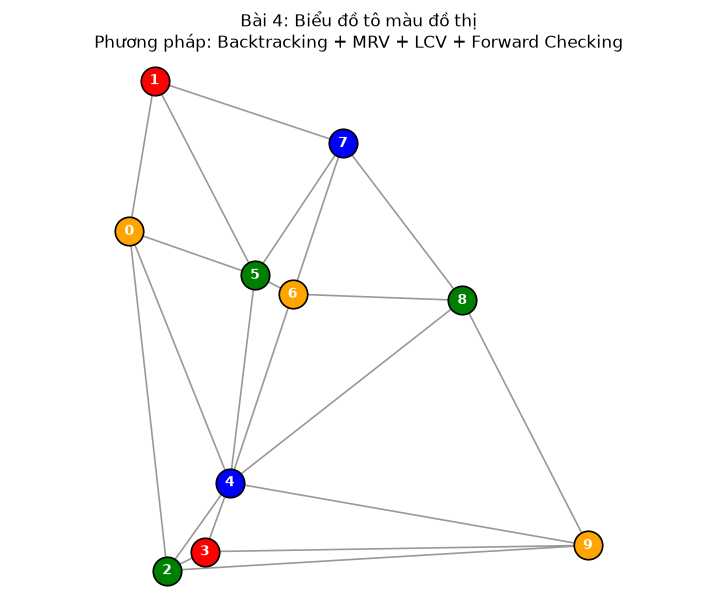

Phương pháp: Backtracking + MRV + LCV + Forward Checking
Số đỉnh: 10
Số cạnh/ràng buộc: 21
Phép tô màu hợp lệ: True


In [15]:
# Biểu đồ tô màu cho Bài 4
# Ưu tiên nghiệm Backtracking đã tìm được; nếu không có thì thử Min-Conflicts.
part4_solution = res if ('res' in globals() and valid_coloring(res, csp)) else None
part4_method = "Backtracking + MRV + LCV + Forward Checking"

if part4_solution is None:
    part4_solution, part4_mc_stats = min_conflicts(csp, max_steps=20000,
                                                   max_restarts=20, seed=2026)
    part4_method = "Min-Conflicts"

if part4_solution is not None and valid_coloring(part4_solution, csp):
    plt.figure(figsize=(9, 7))
    plt.triplot(points[:, 0], points[:, 1], tri.simplices,
                color="gray", linewidth=1.2, alpha=0.8)
    for vertex in range(len(points)):
        color = part4_solution[str(vertex)]
        plt.scatter(points[vertex, 0], points[vertex, 1], s=420,
                    c=color, edgecolors="black", linewidths=1.2, zorder=3)
        plt.annotate(str(vertex), points[vertex, :], color="white",
                     fontsize=10, weight="bold", ha="center", va="center", zorder=4)
    plt.title(f"Bài 4: Biểu đồ tô màu đồ thị\nPhương pháp: {part4_method}")
    plt.axis("equal")
    plt.axis("off")
    plt.show()
    print("Phương pháp:", part4_method)
    print("Số đỉnh:", len(csp["variables"]))
    print("Số cạnh/ràng buộc:", len(csp["constraints"]))
    print("Phép tô màu hợp lệ:", valid_coloring(part4_solution, csp))
else:
    print("Chưa tìm được phép tô màu hợp lệ trong giới hạn tìm kiếm đã đặt.")
    print("Điều này chưa đủ để kết luận đồ thị vô nghiệm với số màu hiện tại.")
